<a href="https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-1/01-que-es-machine-learning/solucion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Solución 1.1 · ¿Qué es Machine Learning?

**Serie:** Del Excel al Machine Learning · **Temporada 1** · 🎬 Video próximamente

Estas son las respuestas del ejercicio. Si la tuya es distinta pero da el mismo resultado, ¡también está bien! En programación suele haber más de una forma de llegar a la respuesta.

### Prepara los datos

Ejecuta estas dos celdas. Algunos ejercicios usan variables de los anteriores, así que **ejecútalos en orden**.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression

DATOS = "https://raw.githubusercontent.com/PercyTechX/del-excel-al-ml/main/datos/"

In [2]:
ventas = pd.read_csv(DATOS + "ventas.csv")
productos = pd.read_csv(DATOS + "productos.csv")

ventas.shape

(50000, 11)

### 1. ¿Regla o Machine Learning?

Responde en un comentario, con `#`, y explica por qué:

- a) Calcular el IGV de una factura.
- b) Estimar cuántas cajas de panetón pedirá el próximo diciembre un cliente.
- c) Saber si una venta tiene descuento por volumen.
- d) Estimar qué ventas al crédito se pagarán con atraso.

In [3]:
# a) Regla: el IGV es un porcentaje fijo.
# b) Machine Learning: no hay fórmula, pero hay historia de otros años.
# c) Regla: la empresa la definió, y es exacta.
# d) Machine Learning: nadie conoce la regla, pero hay historia de pagos.

### 2. Otro producto, sin decir el precio

Filtra las ventas del producto `P001` sin descuento y guárdalas en `arroz`. Deben quedar `157` filas.

Separa `x` (`cantidad`) e `y` (`total`), y entrena un modelo. Muestra lo que aprendió con `.coef_`, redondeado a 2 decimales. Comprueba si coincide con el precio de `P001` en `productos`.

In [4]:
arroz = ventas[(ventas["id_producto"] == "P001") & (ventas["descuento"] == 0)]

print(len(arroz))

x = arroz[["cantidad"]]
y = arroz["total"]

modelo = LinearRegression()
modelo.fit(x, y)

print(modelo.coef_.round(2))

productos[productos["id_producto"] == "P001"][["nombre", "precio"]]

157
[99.5]


,nombre,precio
0,Arroz extra 5 kg,99.5


### 3. Una predicción

Con ese modelo, predice el total de una venta de 3 presentaciones. Debe dar `298.5`. Comprueba a mano: ¿cuánto da multiplicar 3 por el precio?

In [5]:
nuevo = pd.DataFrame({"cantidad": [3]})

print(modelo.predict(nuevo).round(2))
print(3 * 99.5)

[298.5]
298.5


### 4. ¿Y con los descuentos?

Ahora repítelo con **todas** las ventas de `P001`, también las que tienen descuento. Guarda el modelo en otra variable y muestra su `.coef_`, redondeado a 2 decimales. Debe dar `92.44`, menos que el precio.

¿Por qué? Responde en un comentario.

In [6]:
todas = ventas[ventas["id_producto"] == "P001"]

modelo_todas = LinearRegression()
modelo_todas.fit(todas[["cantidad"]], todas["total"])

print(modelo_todas.coef_.round(2))

# Es menor porque las ventas grandes tienen descuento: cada presentación adicional
# sale, en promedio, más barata. Una sola recta promedia todos esos casos.

[92.44]


### 5. El error de principiante

Ejecuta esto y lee el error. Luego corrígelo:

```python
modelo = LinearRegression()
modelo.fit(arroz["cantidad"], arroz["total"])
```

In [7]:
# El error es un ValueError: pandas le entregó una sola columna.
# El modelo espera una tabla, y por eso x lleva doble corchete.
modelo = LinearRegression()
modelo.fit(arroz[["cantidad"]], arroz["total"])

print(modelo.coef_.round(2))

[99.5]


### 6. Otro cliente

Grafica las compras por mes del cliente `C0100`, como en la clase. ¿Podrías escribir una fórmula exacta para su próximo mes? Responde en un comentario.

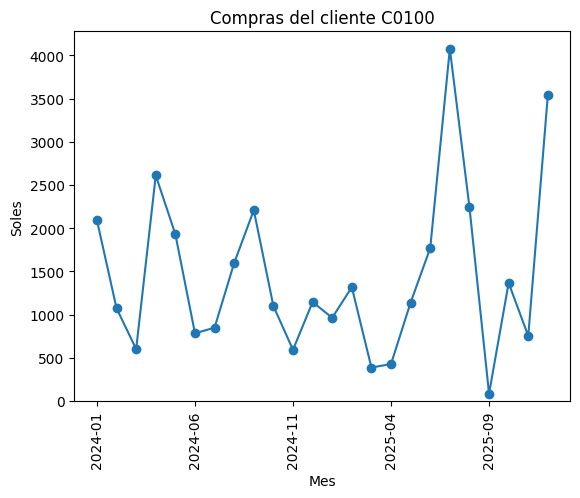

In [8]:
cliente = ventas[ventas["id_cliente"] == "C0100"]
por_mes = cliente.groupby(cliente["fecha"].str[:7])["total"].sum()

por_mes.plot(
    kind="line",
    marker="o",
    title="Compras del cliente C0100",
    xlabel="Mes",
    ylabel="Soles",
    rot=90,
    ylim=(0, None),
)
plt.show()

# No hay fórmula exacta: sus compras suben y bajan. Se puede estimar, pero no calcular.

## 🎉 ¡Bien hecho!

Nos vemos en el **episodio 1.2: Tu primer modelo, la recta**.

---

*Del Excel al Machine Learning* · por [Percy Nazario](https://www.linkedin.com/in/percy-nazario/) · [Repositorio](https://github.com/PercyTechX/del-excel-al-ml) · Contenido bajo licencia CC BY 4.0